In [1]:
import lightkurve as lk
import numpy as np


from IPython.core import display 
from IPython.core.display import HTML
display.display_html("<style>.container { width:100% !important; }</style>")

import matplotlib.pyplot as plt
import os
import astropy.units as u
%matplotlib inline

from elisa import settings
from elisa.analytics import LCData, LCBinaryAnalyticsTask
import pandas as pd

# setting up a custom logging config to prevent unreasonably long log messages during fit
settings.configure(LOG_CONFIG='default')

c:\Users\mynam\anaconda3\envs\elisa_env\Lib\site-packages\elisa\conf\settings.py:400: DeprecationWarning: Variable `atlas` in configuration section `support` is not longer supported and will be removed in future version.
Use atmosphere definition as initial parameter for given celestial object
  warnings.warn("Variable `atlas` in configuration section `support` is not "


In [2]:
obj = 'tic197183006'
LC_data = LCData.load_from_file(obj+'_lk_data.dat',delimiter='\t',x_unit=u.day)
period = 0.5663165151668149 #from tess
t0 = 1843.227497003016 #from tess

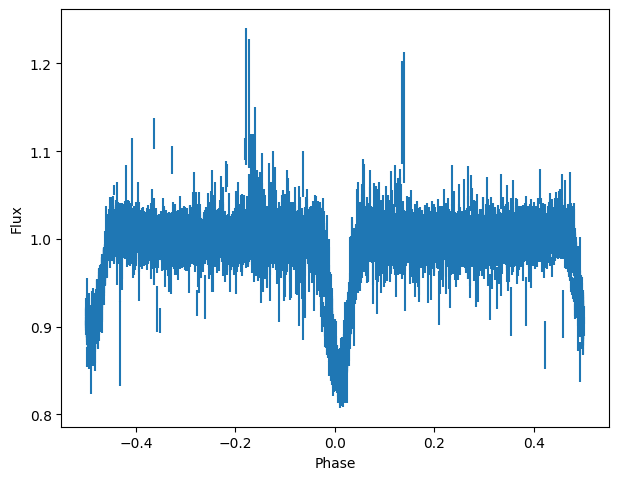

In [3]:
LC_data.convert_to_phases(period,t0,centre=0.0)
LC_data.plot.display_observation()

In [4]:
lc_init_params = {
    'system':{
        'inclination':{
            'value': 89.12307284074389, #MAST
            'fixed': True,
            'unit': u.deg
        },
        'period':{
            'value': 0.5663165151668149, #TESS
            'fixed': True,
            'unit': u.day
        },
        'eccentricity':{
            'value': 0.0, #MAST
            'fixed': True,
        },
        #not sure what this does
        'argument_of_periastron':{
            'value': 45.0,
            'fixed': False,
            'min': 0.0,
            'max': 90.0,
            'unit': u.deg
        },
        'phase_shift':{
            'value': 0.0,
            'fixed': False,
            'min': -0.02,
            'max': 0.02,
        }
    },
    'primary':{
        'mass':{
            'value': 0.28, #from Henry + Jao, 2024, M3.0V
            'fixed': False,
            'min': 0.075, #from Henry + Jao, 2024
            'max': 0.61, #from Henry + Jao, 2024
            'unit': u.solMass
        },
        't_eff':{
            'value': 3325.0, #from TESS
            'fixed': True,
            'unit': u.K
        },
        #not sure what this does
        'surface_potential':{
            'value': 10,
            'fixed': False,
            'min': 3,
            'max': 50,
        },
        'metallicity':{
            'value': 0.0,
            'fixed': True,
        }
    },
    'secondary':{
        'mass':{
            'value': 0.1, #from Henry + Jao, 2024, M3.0V
            'fixed': False,
            'min': 0.075, #from Henry + Jao, 2024
            'max': 0.2, #from Henry + Jao, 2024
            'unit': u.solMass
        },
        't_eff':{
            'value': 3000.0, #from TESS
            'fixed': False,
            'min': 2900.0,
            'max': 4000.0,
            'unit': u.K
        },
        #not sure what this does
        'surface_potential':{
            'value': 10,
            'fixed': False,
            'min': 3,
            'max': 50,
        },
        'metallicity':{
            'value': 0.0,
            'fixed': True,
        }
    }
}

In [5]:
lst_sqr_task = LCBinaryAnalyticsTask(data={'TESS': LC_data}, method='least_squares', expected_morphology="detached")
#LCBinaryAnalyticsTask?

2025-04-29 08:25:01,572 - 20164 - observer.observer - INFO: initialising Observer instance


2025-04-29 08:25:01,582 - 20164 - binary_system.system - INFO: initialising object BinarySystem
2025-04-29 08:25:01,609 - 20164 - binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.
2025-04-29 08:25:01,609 - 20164 - observer.observer - INFO: observation is running
2025-04-29 08:25:02,169 - 20164 - elisa.atm - INFO: time 0.0
2025-04-29 08:25:02,186 - 20164 - elisa.atm - INFO: time 0.0
2025-04-29 08:25:02,353 - 20164 - observer.observer - INFO: observation finished


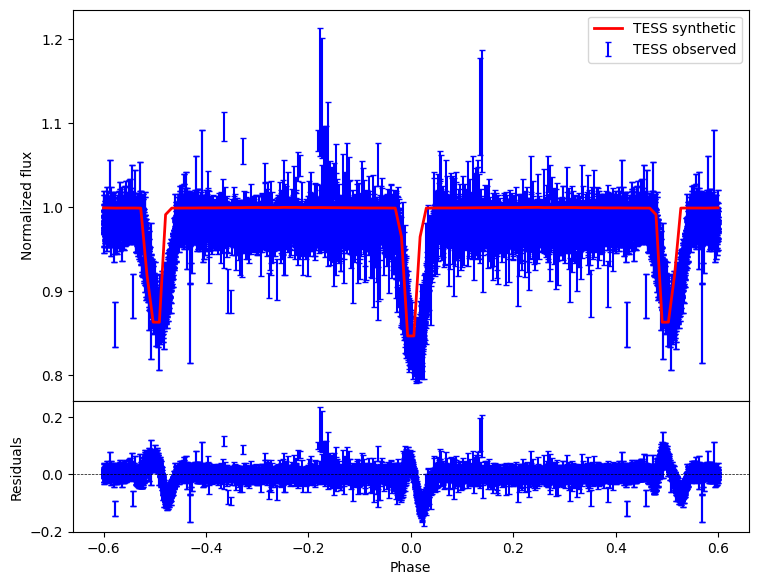

In [6]:
lst_sqr_task.set_result(lc_init_params)  
# lst_sqr_task.load_result(filename)  # in case that your staring parameters are stored as a json in file 

lst_sqr_task.plot.model(number_of_points=100, start_phase=-0.6, stop_phase=0.6)

In [7]:
settings.configure(NUMBER_OF_PROCESSES=os.cpu_count())  # this will make sure to utilize all available processors

In [18]:
param_file = 'demo_data/assets/lc_least_squares.json'

# this part can take a while to complete in case of eccentric orbit
#lst_sqr_result = lst_sqr_task.fit(x0=lc_init_params, interp_treshold=100, samples='adaptive')
#lst_sqr_task.save_result(param_file)

# load pre-calculated results if you don't want to wait
lst_sqr_task.load_result(param_file)
lst_sqr_result = lst_sqr_task.get_result()
lst_sqr_task.fit_summary()

2025-04-29 09:33:58,335 - 20164 - binary_system.system - INFO: initialising object BinarySystem
2025-04-29 09:33:58,353 - 20164 - binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.

BINARY SYSTEM
Parameter                                          value            -1 sigma            +1 sigma                unit    status                                            
------------------------------------------------------------------------------------------------------------------------------
Mass ratio (q=M_2/M_1):                            0.426                                                                derived                                           
Semi major axis (a):                               2.056                                                      solRad    derived                                           
Inclination (i):                                   89.12                

2025-04-29 09:33:59,369 - 20164 - observer.observer - INFO: initialising Observer instance
2025-04-29 09:33:59,378 - 20164 - binary_system.system - INFO: initialising object BinarySystem


2025-04-29 09:33:59,441 - 20164 - binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.
2025-04-29 09:33:59,441 - 20164 - observer.observer - INFO: observation is running
2025-04-29 09:33:59,627 - 20164 - elisa.atm - INFO: time 0.0010006427764892578
2025-04-29 09:33:59,634 - 20164 - elisa.atm - INFO: time 0.001004934310913086
2025-04-29 09:34:00,252 - 20164 - observer.observer - INFO: observation finished


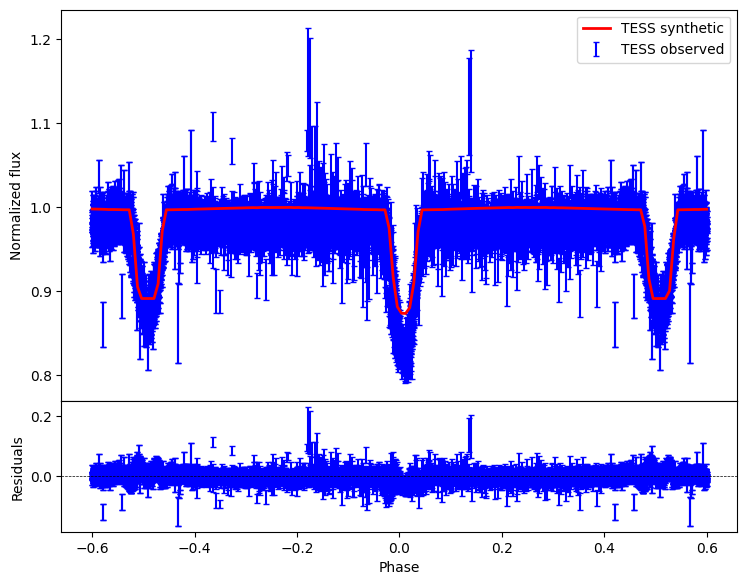

In [19]:
#lst_sqr_task.save_result(param_file)
lst_sqr_task.plot.model(number_of_points=150, start_phase=-0.6, stop_phase=0.6)

In [20]:
settings.configure(**{
    "NUMBER_OF_PROCESSES": 1,  # we want a single process to handle the light curve integration 
    "NUMBER_OF_MCMC_PROCESSES":os.cpu_count()  # in this case, multiple MCMC walkers will be evaluated at once, each MCMC walker will use single core to obtain the curve
})

In [21]:
mcmc_init_params = {
    'system':{
        'inclination':{
            'value': lst_sqr_result['system']['inclination']['value'], #MAST
            'fixed': True,
            'unit': u.deg
        },
        'period':{
            'value': lst_sqr_result['system']['period']['value'], #TESS
            'fixed': True,
            'unit': u.day
        },
        'eccentricity':{
            'value': lst_sqr_result['system']['eccentricity']['value'], #MAST
            'fixed': True,
        },
        #not sure what this does
        'argument_of_periastron':{
            'value': lst_sqr_result['system']['argument_of_periastron']['value'],
            'fixed': False,
            'sigma':30,
            'min': 0.0,
            'max': 90.0,
            'unit': u.deg
        },
        'phase_shift':{
            'value': lst_sqr_result['system']['phase_shift']['value'],
            'fixed': False,
            'sigma': 0.005,
            'min': -0.02,
            'max': 0.02,
        }
    },
    'primary':{
        'mass':{
            'value': lst_sqr_result['primary']['mass']['value'], #from Henry + Jao, 2024, M3.0V
            'fixed': False,
            'sigma': 0.05,
            'min': 0.075, #from Henry + Jao, 2024
            'max': 0.61, #from Henry + Jao, 2024
            'unit': u.solMass
        },
        't_eff':{
            'value': lst_sqr_result['primary']['t_eff']['value'], #from TESS
            'fixed': False,
            'sigma': 100,
            'min': 2900,
            'max': 4000,
            'unit': u.K
        },
        #not sure what this does
        'surface_potential':{
            'value': lst_sqr_result['primary']['surface_potential']['value'],
            'fixed': False,
            'sigma': 5,
            'min': 3,
            'max': 50,
        },
        'metallicity':{
            'value': lst_sqr_result['primary']['metallicity']['value'],
            'fixed': True,
        }
    },
    'secondary':{
        'mass':{
            'value': lst_sqr_result['secondary']['mass']['value'], #from Henry + Jao, 2024, M3.0V
            'fixed': False,
            'sigma': 0.05,
            'min': 0.075, #from Henry + Jao, 2024
            'max': 0.2, #from Henry + Jao, 2024
            'unit': u.solMass
        },
        't_eff':{
            'value': lst_sqr_result['secondary']['t_eff']['value'], #from TESS
            'fixed': False,
            'sigma': 100,
            'min': 2900.0,
            'max': 4000.0,
            'unit': u.K
        },
        #not sure what this does
        'surface_potential':{
            'value': lst_sqr_result['secondary']['surface_potential']['value'],
            'fixed': False,
            'sigma': 5,
            'min': 3,
            'max': 50,
        },
        'metallicity':{
            'value': lst_sqr_result['secondary']['metallicity']['value'],
            'fixed': True,
        }
    }
}

In [22]:
mcmc_task = LCBinaryAnalyticsTask(data={'TESS': LC_data}, method='mcmc', expected_morphology='detached')

In [23]:
param_file = 'demo_data/assets/lc_mcmc_params.json'
chain_file = 'demo_data/assets/lc_mcmc_chain.json'

# MCMC sampling takes a long time
mcmc_params = mcmc_task.fit(x0=mcmc_init_params, nsteps=1000, nwalkers=100, burn_in=0, interp_treshold=100, progress=True, fit_id=chain_file, save=True, samples='adaptive')
mcmc_task.save_result(param_file)

# due to very time consuming nature of a MCMC sampling, we will load pre-calculated results
#mcmc_task.load_result(param_file)
#mcmc_task.load_chain(chain_file)
#mcmc_task.fit_summary()

2025-04-29 09:34:05,487 - 20164 - observer.observer - INFO: initialising Observer instance
2025-04-29 09:34:05,495 - 20164 - analytics.binary_fit.shared - INFO: Generating equidistant samples along the light curve using adaptive sampling method
2025-04-29 09:34:05,496 - 20164 - observer.observer - INFO: initialising Observer instance
2025-04-29 09:34:05,499 - 20164 - binary_system.system - INFO: initialising object BinarySystem
2025-04-29 09:34:05,529 - 20164 - binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.
2025-04-29 09:34:05,530 - 20164 - observer.observer - INFO: observation is running
2025-04-29 09:34:05,709 - 20164 - elisa.atm - INFO: time 0.014871358871459961
2025-04-29 09:34:05,725 - 20164 - elisa.atm - INFO: time 0.0
2025-04-29 09:34:08,546 - 20164 - observer.observer - INFO: observation finished
2025-04-29 09:34:08,552 - 20164 - analytics.binary_fit.mcmc - INFO: starting mcmc
2025-0

 17%|█▋        | 172/1000 [29:50<3:00:39, 13.09s/it]

2025-04-29 10:04:11,768 - 20164 - analytics.binary_fit.mixins - INFO: MCMC chain, variable`s fitable and normalization constants were stored in: demo_data/assets\lc_mcmc_chain.json


 31%|███       | 312/1000 [59:50<2:25:16, 12.67s/it]

2025-04-29 10:34:12,635 - 20164 - analytics.binary_fit.mixins - INFO: MCMC chain, variable`s fitable and normalization constants were stored in: demo_data/assets\lc_mcmc_chain.json


...

2025-04-29 12:04:31,484 - 20164 - analytics.binary_fit.mixins - INFO: MCMC chain, variable`s fitable and normalization constants were stored in: demo_data/assets\lc_mcmc_chain.json


 89%|████████▉ | 894/1000 [3:00:12<20:24, 11.55s/it]

2025-04-29 12:34:35,184 - 20164 - analytics.binary_fit.mixins - INFO: MCMC chain, variable`s fitable and normalization constants were stored in: demo_data/assets\lc_mcmc_chain.json


100%|██████████| 1000/1000 [3:19:34<00:00, 11.97s/it]


2025-04-29 12:53:56,950 - 20164 - analytics.binary_fit.mixins - INFO: MCMC chain, variable`s fitable and normalization constants were stored in: demo_data/assets\lc_mcmc_chain.json
2025-04-29 12:53:56,967 - 20164 - observer.observer - INFO: initialising Observer instance
2025-04-29 12:53:56,982 - 20164 - binary_system.system - INFO: initialising object BinarySystem
2025-04-29 12:53:57,028 - 20164 - binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.
2025-04-29 12:53:57,028 - 20164 - observer.observer - INFO: observation is running
2025-04-29 12:53:57,219 - 20164 - elisa.atm - INFO: time 0.0
2025-04-29 12:53:57,234 - 20164 - elisa.atm - INFO: time 0.0
2025-04-29 12:53:57,652 - 20164 - observer.observer - INFO: observation finished
2025-04-29 12:53:57,693 - 20164 - analytics.binary_fit.lc_fit - INFO: Fitting and processing of results finished successfully.
2025-04-29 12:53:57,731 - 20164 - binary_s

2025-04-29 12:53:57,789 - 20164 - observer.observer - INFO: initialising Observer instance
2025-04-29 12:53:57,789 - 20164 - binary_system.system - INFO: initialising object BinarySystem
2025-04-29 12:53:57,821 - 20164 - binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.
2025-04-29 12:53:57,822 - 20164 - observer.observer - INFO: observation is running
2025-04-29 12:53:57,993 - 20164 - elisa.atm - INFO: time 0.0
2025-04-29 12:53:58,000 - 20164 - elisa.atm - INFO: time 0.0
2025-04-29 12:53:58,519 - 20164 - observer.observer - INFO: observation finished


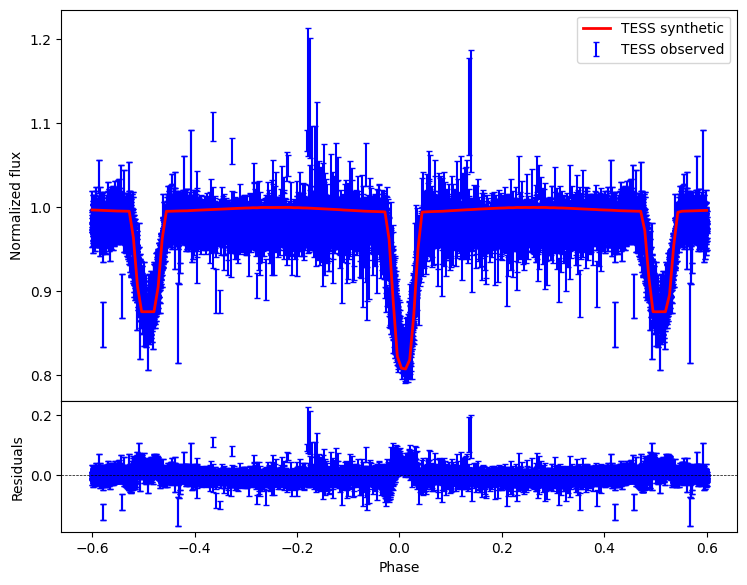

In [24]:
mcmc_task.plot.model(number_of_points=150, start_phase=-0.6, stop_phase=0.6)

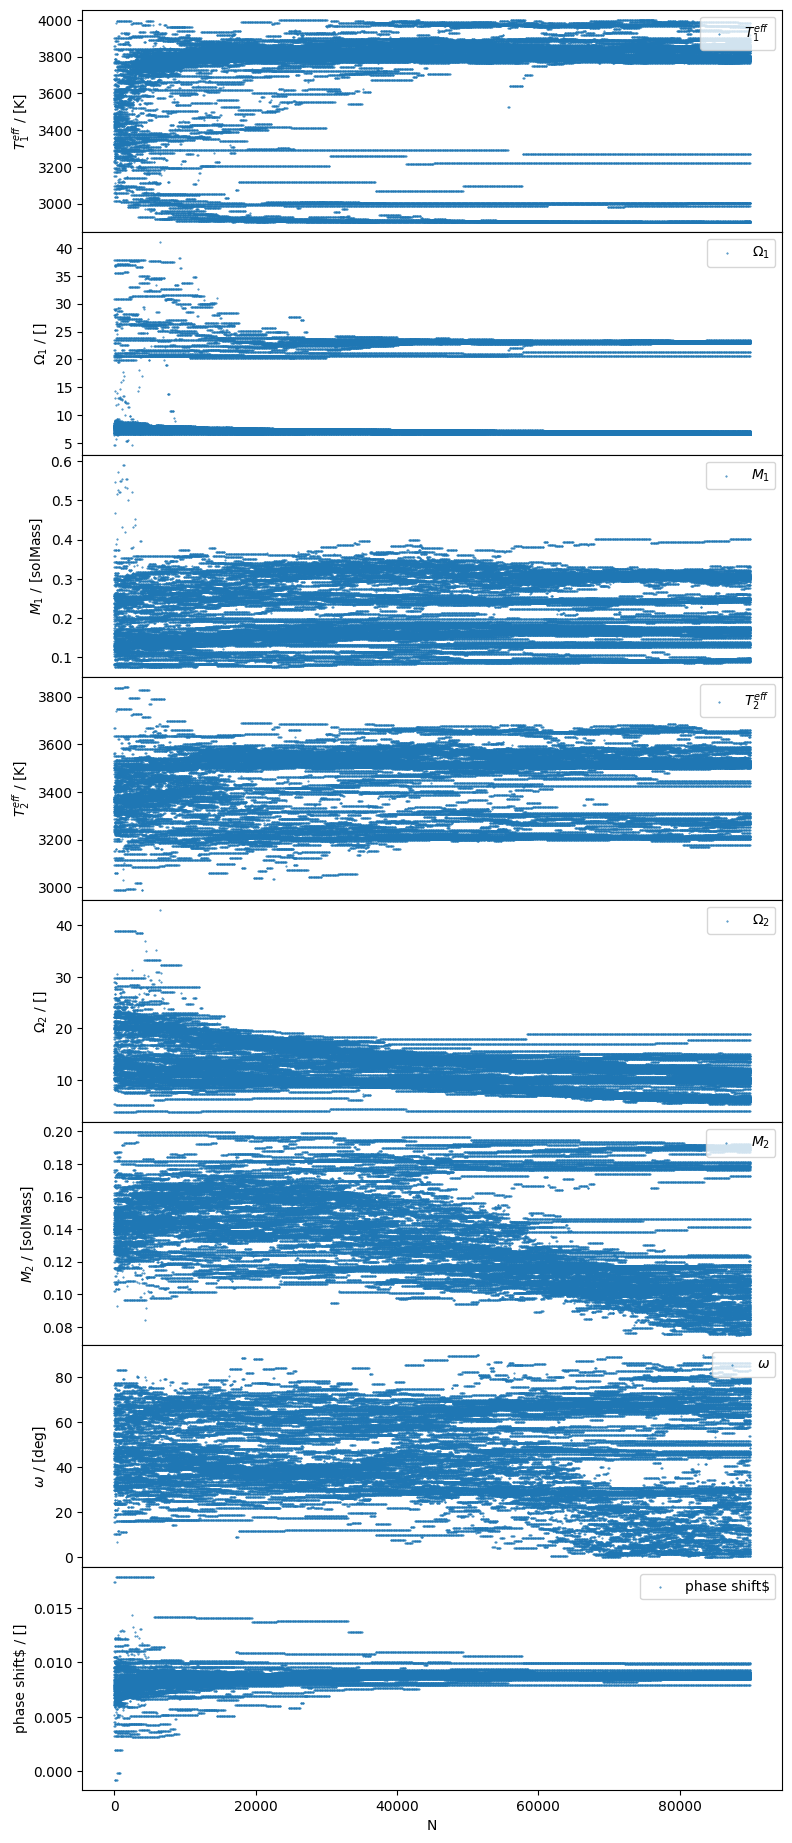

2025-04-29 13:19:39,452 - 20164 - root - WARNING: Too few points to create valid contours
2025-04-29 13:19:39,919 - 20164 - root - WARNING: Too few points to create valid contours
2025-04-29 13:19:39,940 - 20164 - root - WARNING: Too few points to create valid contours


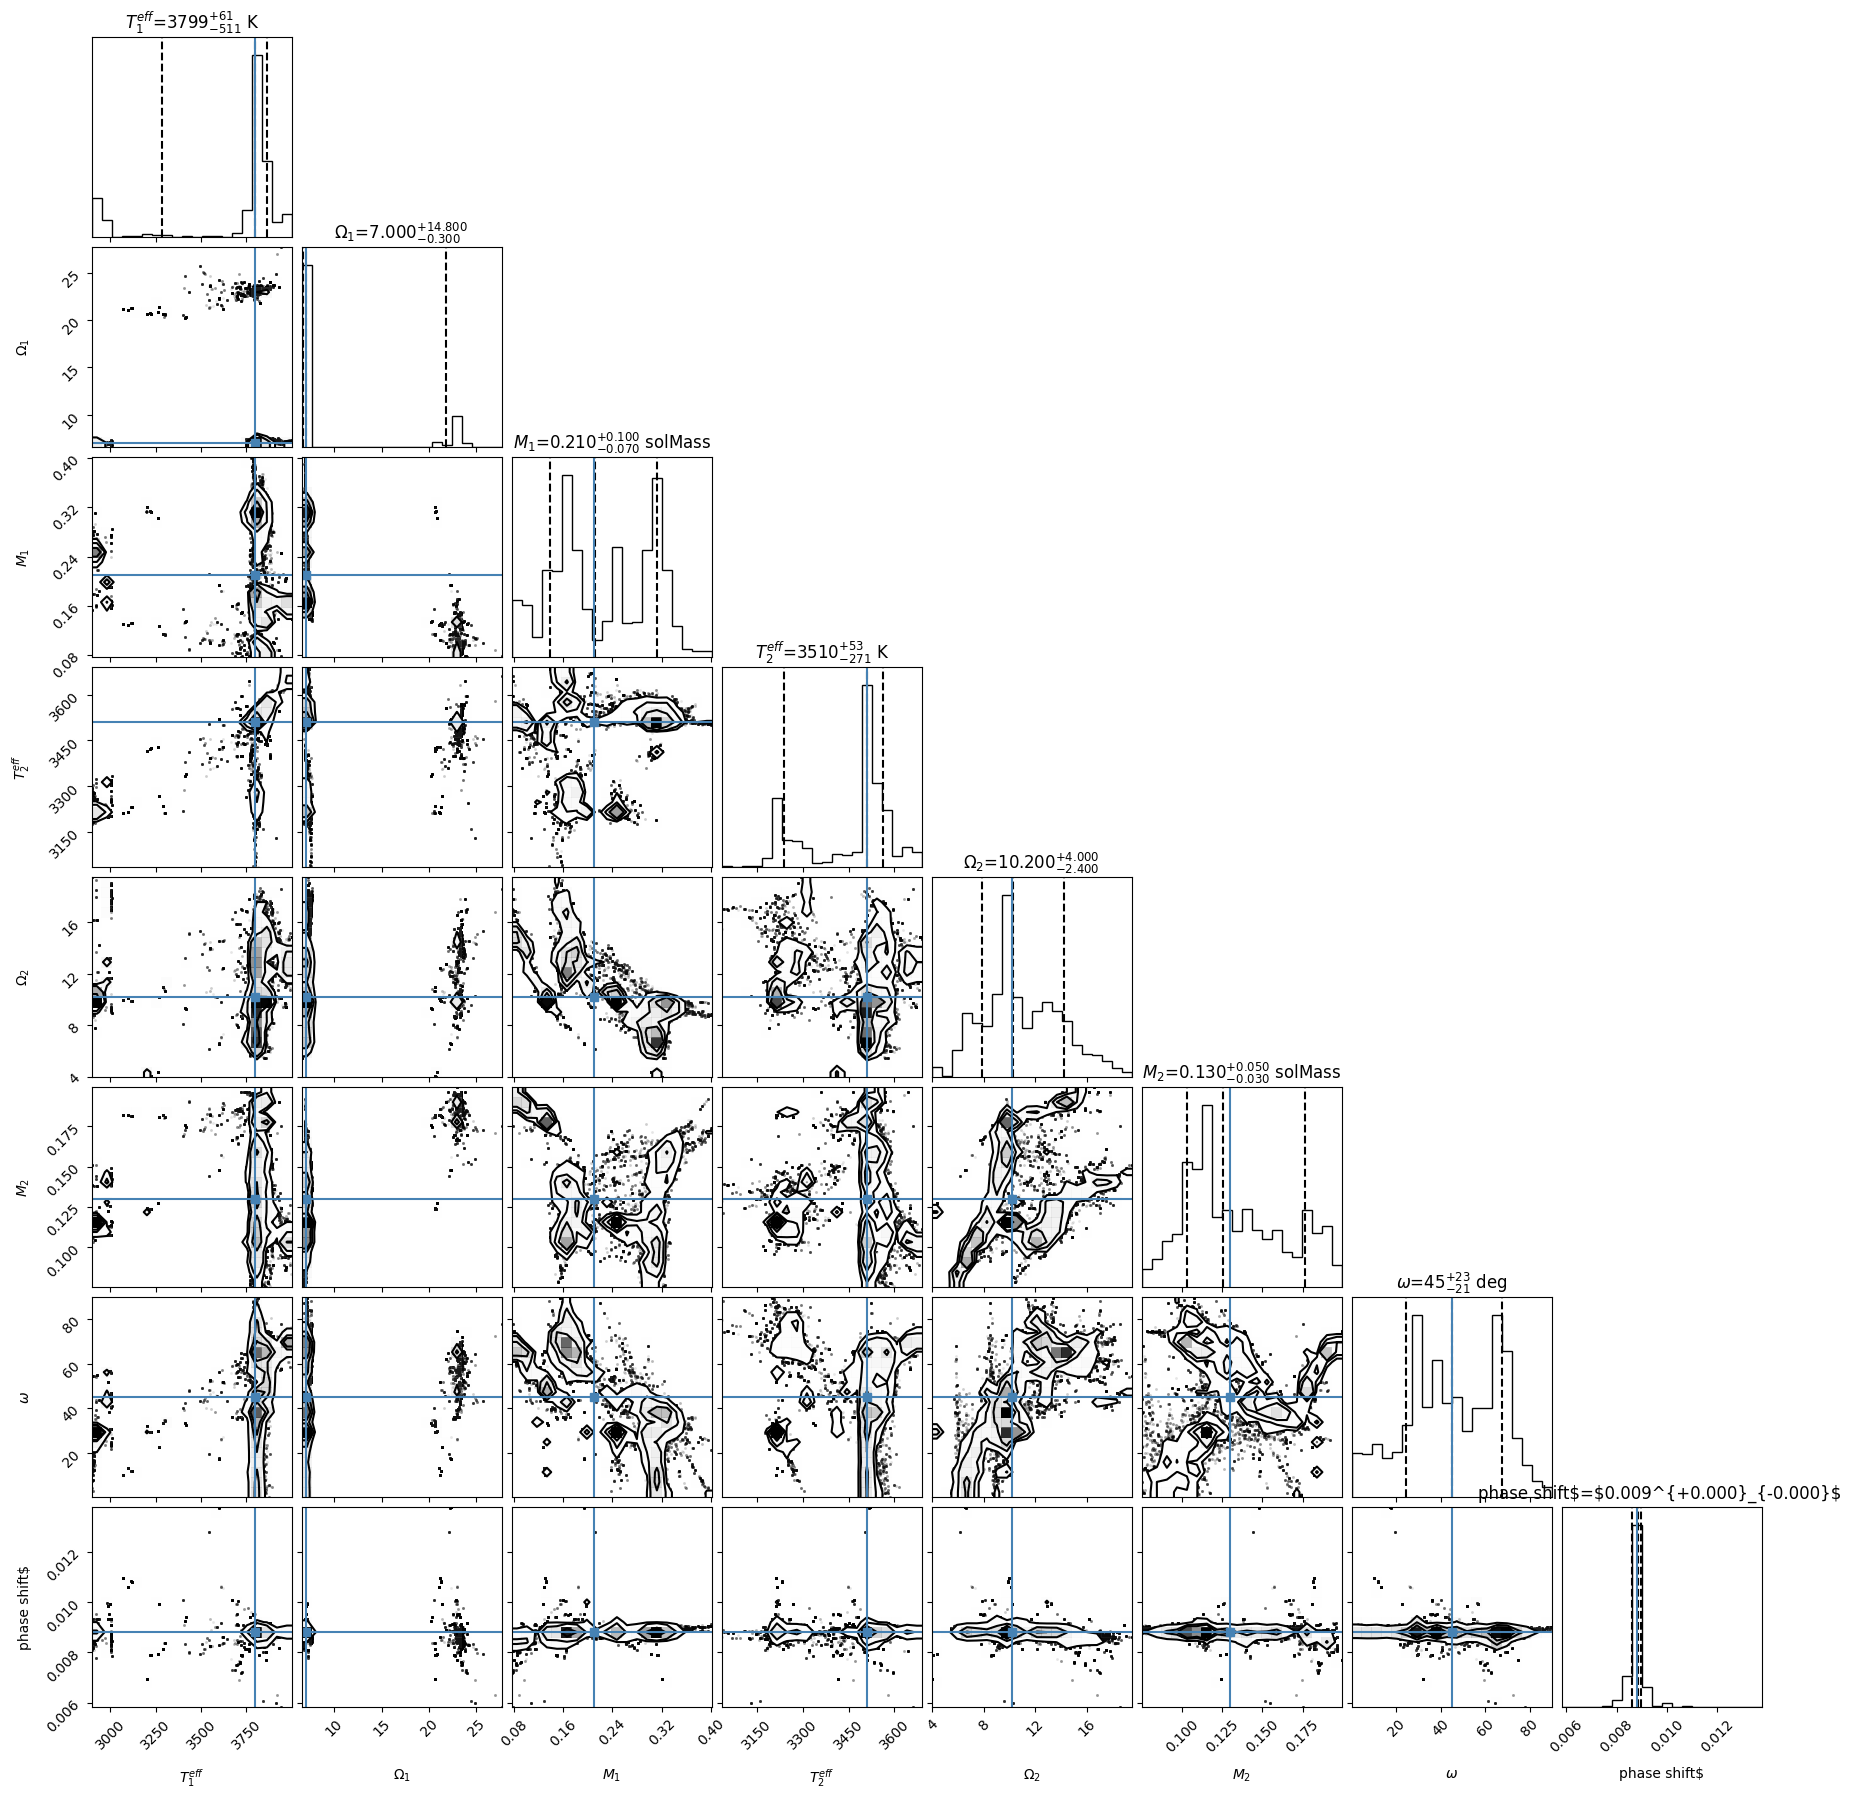

In [26]:
mcmc_task.plot.traces()
mcmc_task.load_chain(chain_file,discard=30000)
mcmc_task.plot.corner(truths=True)